# ETH Quarterly Options Analysis

Quarterly options are the **largest, most institutional** expiry on Deribit.

They expire on the **last Friday of March, June, September, and December at 1:30 PM IST** (08:00 UTC) [citation:2][citation:7].

These are multi-billion dollar events. On a recent quarterly expiry, **$2.1 billion in ETH options** settled in a single session [citation:1].

**This notebook analyzes:**

1. The next quarterly expiry date in IST
2. Contract count and OI structure (the deepest on the chain)
3. IV smile at the quarterly tenor
4. Greeks profile (low theta, high vega)
5. Theta decay over the quarter
6. Breakeven per strike
7. Liquidity (institutional-grade)
8. Best quarterly contract for a buyer
9. Quarterly vs monthly vs weekly
10. The quarterly buyer's verdict

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from datetime import datetime, timezone, timedelta
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (13, 5)

DERIBIT = 'https://www.deribit.com/api/v2/public'
CURRENCY = 'ETH'
IST_OFFSET = timedelta(hours=5, minutes=30)

def to_ist(dt):
    if dt.tzinfo is None:
        dt = dt.replace(tzinfo=timezone.utc)
    return dt.astimezone(timezone(IST_OFFSET))

print('ready')

ready


## 1. Fetch chain and identify quarterly expiries

Quarterly = **last Friday of March, June, September, December** [citation:7].

In [2]:
def fetch_chain(currency):
    r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                     params={'currency': currency, 'kind': 'option'}, timeout=20)
    r.raise_for_status()
    return r.json()['result']


def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4:
        return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(
            tzinfo=timezone.utc, hour=8, minute=0)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None


raw = fetch_chain(CURRENCY)
now_ms = int(time.time() * 1000)

rows = []
for r in raw:
    p = parse_name(r['instrument_name'])
    if p is None: continue
    rows.append({
        'instrument': r['instrument_name'],
        'expiry': p[0],
        'strike': p[1],
        'kind': p[2],
        'days': (p[0] - now_ms) / 86_400_000,
        'mark': r.get('mark_price'),
        'bid': r.get('bid_price'),
        'ask': r.get('ask_price'),
        'iv': r.get('mark_iv'),
        'oi': r.get('open_interest') or 0,
        'volume': r.get('volume') or 0,
        'underlying': r.get('underlying_price'),
    })

df_all = pd.DataFrame(rows)
df_all['expiry_dt'] = pd.to_datetime(df_all.expiry, unit='ms', utc=True).dt.tz_convert(None)
df_all['iv_dec'] = df_all['iv'] / 100.0
df_all['spread_pct'] = (df_all['ask'] - df_all['bid']) / ((df_all['ask'] + df_all['bid']) / 2 + 1e-9)

spot = df_all['underlying'].dropna().iloc[0] if df_all['underlying'].notna().any() else df_all.strike.median()

# Quarterly = last Friday of Mar/Jun/Sep/Dec
QUARTERLY_MONTHS = [3, 6, 9, 12]

def is_quarterly(dt):
    if dt.weekday() != 4:  # Friday
        return False
    if dt.month not in QUARTERLY_MONTHS:
        return False
    next_friday = dt + timedelta(days=7)
    return next_friday.month != dt.month

all_expiries = df_all.groupby('expiry_dt').agg(
    contracts=('instrument', 'count'),
    days=('days', 'first'),
    total_oi=('oi', 'sum'),
    volume=('volume', 'sum'),
).reset_index().sort_values('days')
all_expiries = all_expiries[all_expiries.days > 0]

quarterly_expiries = all_expiries[
    all_expiries.expiry_dt.apply(lambda d: is_quarterly(d.to_pydatetime()))
].reset_index(drop=True)

print(f'ETH spot: ${spot:,.2f}\n')
print('NEXT QUARTERLY EXPIRIES (last Friday of Mar/Jun/Sep/Dec at 1:30 PM IST):\n')
for _, e in quarterly_expiries.head(5).iterrows():
    ist = to_ist(e['expiry_dt'].to_pydatetime())
    print(f"  {ist.strftime('%A %d %B %Y - %I:%M %p IST')}  "
          f"({e['days']:.1f}d)  {e['contracts']} contracts  OI: {e['total_oi']:,.0f}")

ETH spot: $2,321.53

NEXT QUARTERLY EXPIRIES (last Friday of Mar/Jun/Sep/Dec at 1:30 PM IST):

  Friday 25 December 2026 - 01:30 PM IST  (60.0d)  88 contracts  OI: 616,891
  Friday 26 March 2027 - 01:30 PM IST  (151.0d)  84 contracts  OI: 215,756
  Friday 25 June 2027 - 01:30 PM IST  (242.0d)  86 contracts  OI: 85,762
  Friday 24 September 2027 - 01:30 PM IST  (333.0d)  78 contracts  OI: 25,607


## 2. Select the nearest quarterly expiry

In [3]:
if len(quarterly_expiries) == 0:
    print('No future quarterly expiries found')
else:
    target = quarterly_expiries.iloc[0]
    q_dt = target['expiry_dt']
    ist_q = to_ist(q_dt.to_pydatetime())
    days_to_q = target['days']

    print(f'Target quarterly expiry: {ist_q.strftime("%A %d %B %Y - %I:%M %p IST")}')
    print(f'Days away: {days_to_q:.1f}')
    print()

    df_q = df_all[df_all.expiry_dt == q_dt].copy()
    print(f'Contracts in this quarterly: {len(df_q)}')
    print(f'Calls: {(df_q.kind=="C").sum()}  Puts: {(df_q.kind=="P").sum()}')

Target quarterly expiry: Friday 25 December 2026 - 01:30 PM IST
Days away: 60.0

Contracts in this quarterly: 88
Calls: 44  Puts: 44


## 3. Quarterly contract overview

**What this tells you:** the size of the largest expiry event. Quarterly OI is usually **5-10x larger** than monthly.

In [4]:
if len(quarterly_expiries) > 0:
    print('=' * 65)
    print(f'QUARTERLY EXPIRY: {ist_q.strftime("%A %d %B %Y - %I:%M %p IST")}')
    print('=' * 65)
    print(f'  Time remaining      : {days_to_q*24:.1f} hours ({days_to_q:.1f} days)')
    print(f'  Total contracts     : {len(df_q)}')
    print(f'  Unique strikes      : {df_q.strike.nunique()}')
    print(f'  Strike range        : ${df_q.strike.min():,.0f} - ${df_q.strike.max():,.0f}')
    print(f'  Call OI             : {df_q[df_q.kind=="C"].oi.sum():,.0f}')
    print(f'  Put OI              : {df_q[df_q.kind=="P"].oi.sum():,.0f}')
    print(f'  Total OI            : {df_q.oi.sum():,.0f}')
    print(f'  Volume today        : {df_q.volume.sum():,.0f}')
    pcr = df_q[df_q.kind=="P"].oi.sum() / max(df_q[df_q.kind=="C"].oi.sum(), 1)
    print(f'  PCR (OI)            : {pcr:.2f}')
    print(f'  ATM IV (nearest)    : {df_q.iloc[(df_q.strike - spot).abs().argsort()[:1]].iv_dec.iloc[0]*100:.1f}%')

QUARTERLY EXPIRY: Friday 25 December 2026 - 01:30 PM IST
  Time remaining      : 1441.1 hours (60.0 days)
  Total contracts     : 88
  Unique strikes      : 44
  Strike range        : $800 - $11,000
  Call OI             : 443,609
  Put OI              : 173,282
  Total OI            : 616,891
  Volume today        : 3,672
  PCR (OI)            : 0.39
  ATM IV (nearest)    : 51.2%


## 4. Strike distribution

**What this tells you:** where institutional money is positioned. The largest bars are the strikes that will matter most at expiry.

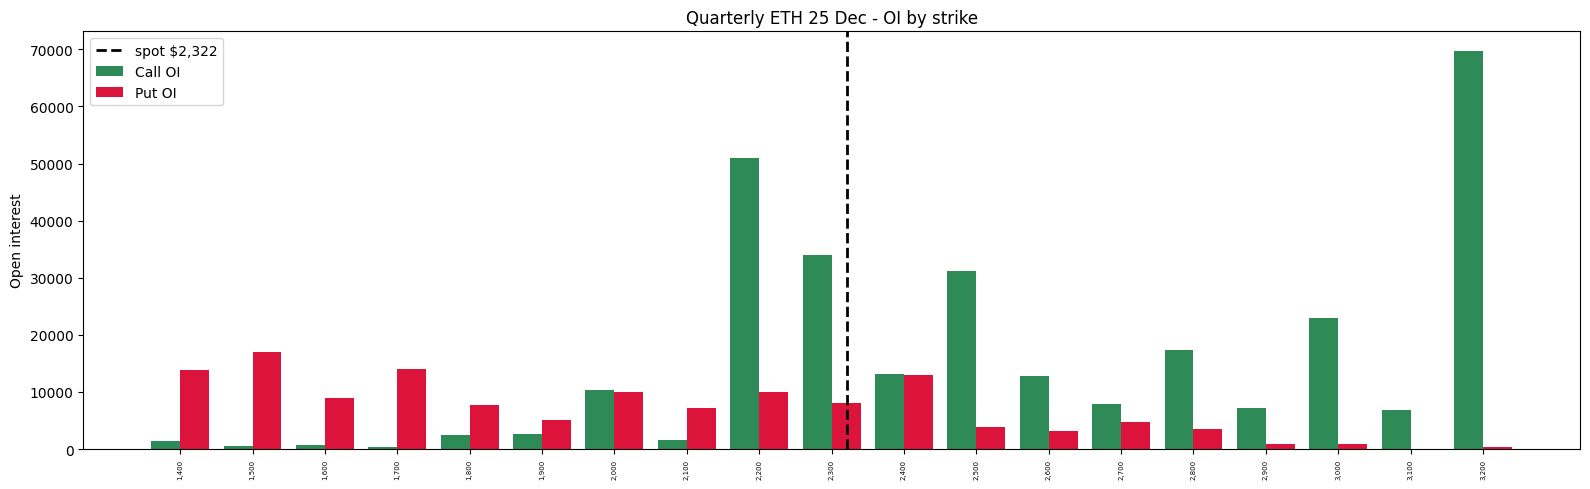

In [5]:
if len(quarterly_expiries) > 0:
    near = df_q[(df_q.strike > spot * 0.6) & (df_q.strike < spot * 1.4)]
    calls = near[near.kind == 'C'].groupby('strike').oi.sum()
    puts  = near[near.kind == 'P'].groupby('strike').oi.sum()

    fig, ax = plt.subplots(figsize=(16, 5))
    all_strikes = sorted(set(calls.index) | set(puts.index))
    x = np.arange(len(all_strikes))
    c_vals = [calls.get(k, 0) for k in all_strikes]
    p_vals = [puts.get(k, 0) for k in all_strikes]

    ax.bar(x - 0.2, c_vals, 0.4, label='Call OI', color='seagreen')
    ax.bar(x + 0.2, p_vals, 0.4, label='Put OI', color='crimson')
    ax.axvline(np.interp(spot, all_strikes, x), color='black', lw=2, ls='--', label=f'spot ${spot:,.0f}')
    ax.set_xticks(x)
    ax.set_xticklabels([f'{s:,.0f}' for s in all_strikes], rotation=90, fontsize=5)
    ax.set_ylabel('Open interest')
    ax.set_title(f'Quarterly ETH {ist_q.strftime("%d %b")} - OI by strike')
    ax.legend()
    plt.tight_layout(); plt.show()

## 5. IV smile at quarterly tenor

**Quarterly IV is usually the lowest** of all tenors. It represents the market's **long-term baseline volatility expectation**.

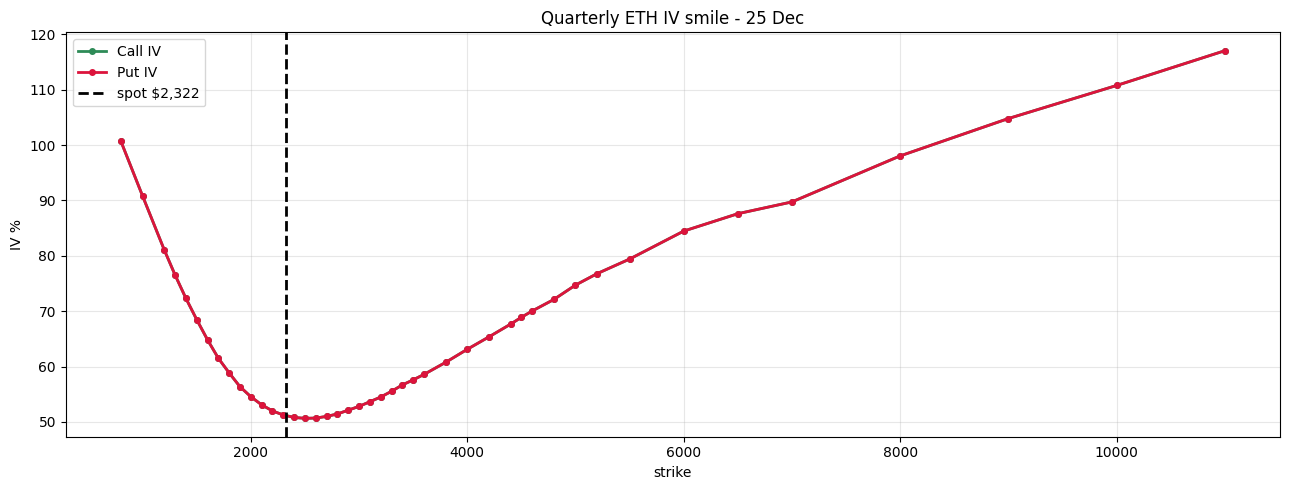


IV comparison across tenors:
  Weekly  (~7d)      : nan%
  Monthly (~30d)     : 59.3%
  Quarterly (last Q) : 68.8%


In [6]:
if len(quarterly_expiries) > 0:
    fig, ax = plt.subplots(figsize=(13, 5))
    c = df_q[(df_q.kind == 'C') & df_q.iv_dec.notna()].sort_values('strike')
    p = df_q[(df_q.kind == 'P') & df_q.iv_dec.notna()].sort_values('strike')
    if len(c) > 0:
        ax.plot(c.strike, c.iv_dec * 100, 'o-', color='seagreen', label='Call IV', lw=2, ms=4)
    if len(p) > 0:
        ax.plot(p.strike, p.iv_dec * 100, 'o-', color='crimson', label='Put IV', lw=2, ms=4)
    ax.axvline(spot, color='black', ls='--', lw=2, label=f'spot ${spot:,.0f}')
    ax.set_xlabel('strike'); ax.set_ylabel('IV %')
    ax.set_title(f'Quarterly ETH IV smile - {ist_q.strftime("%d %b")}')
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    monthly_iv = df_all[df_all.days.between(25, 40)].iv_dec.mean()
    weekly_iv = df_all[df_all.days.between(5, 9)].iv_dec.mean()
    quarterly_iv = df_q.iv_dec.mean()
    print(f'\nIV comparison across tenors:')
    print(f'  Weekly  (~7d)      : {weekly_iv*100:.1f}%')
    print(f'  Monthly (~30d)     : {monthly_iv*100:.1f}%')
    print(f'  Quarterly (last Q) : {quarterly_iv*100:.1f}%')

## 6. Greeks: delta, gamma, theta, vega

**Quarterly options are the most 'positional' on the chain:** lowest theta, highest vega, moderate gamma.

In [7]:
def bs_greeks(S, K, T, sigma, kind):
    if T <= 0 or sigma <= 0:
        return None
    d1 = (np.log(S/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    pdf = norm.pdf(d1)
    delta = norm.cdf(d1) if kind == 'C' else norm.cdf(d1) - 1
    gamma = pdf / (S * sigma * np.sqrt(T))
    vega  = S * pdf * np.sqrt(T) / 100
    theta = -(S * pdf * sigma) / (2 * np.sqrt(T)) / 365
    return {'delta': float(delta), 'gamma': float(gamma),
            'vega': float(vega), 'theta': float(theta)}

if len(quarterly_expiries) > 0:
    greeks = []
    for _, r in df_q.iterrows():
        if pd.isna(r.iv_dec) or r.days <= 0: continue
        g = bs_greeks(spot, r.strike, r.days/365, r.iv_dec, r.kind)
        if g:
            greeks.append({**r.to_dict(), **g})
    gk = pd.DataFrame(greeks)
    print(f'Quarterly contracts with Greeks: {len(gk)}')
    gk[['strike', 'kind', 'days', 'iv_dec', 'delta', 'gamma', 'vega', 'theta']].sort_values(['kind', 'strike']).head(15)

Quarterly contracts with Greeks: 88


## 7. Theta decay - the slowest bleed on the chain

**Quarterly theta is almost painless.** At 90 days out, an ATM option loses only 0.5-1% of premium per day. This is why institutions use quarterly.

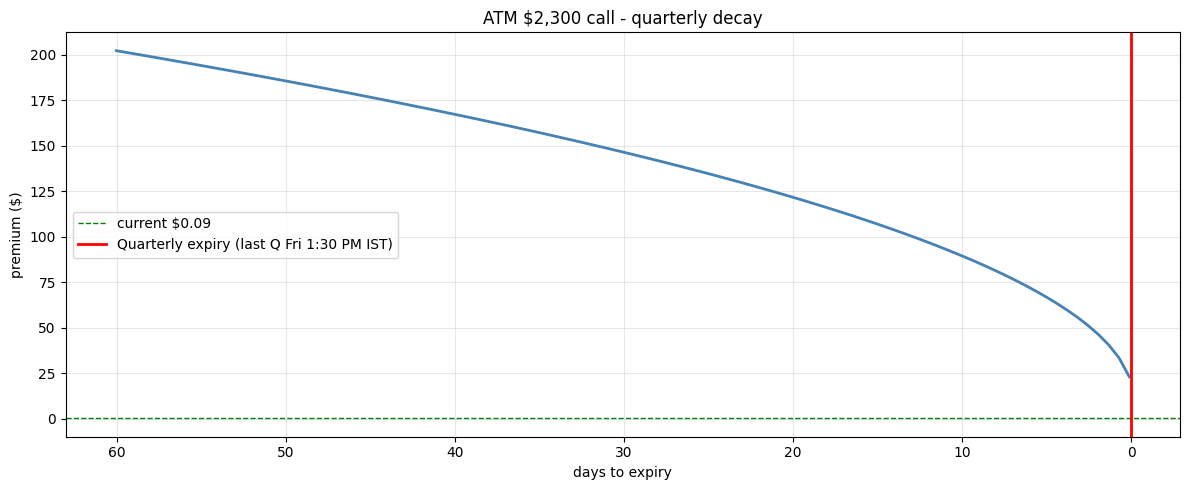

ATM $2,300 call:
  Current mark : $0.09
  Days left    : 60.0
  Theta/day    : $1.59
  Theta as % of premium: 1785.087% per day
  (Compare: daily ~10-50%, weekly ~2-5%, monthly ~1-2%)


In [8]:
if len(quarterly_expiries) > 0:
    atm = gk.iloc[(gk.strike - spot).abs().argsort()[:1]].iloc[0]
    K, sigma = atm.strike, atm.iv_dec
    days_left = atm.days

    days_range = np.linspace(days_left, 0.1, 100)
    prices = []
    for d in days_range:
        T = d / 365
        if T <= 0: break
        d1 = (np.log(spot/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        price = spot * norm.cdf(d1) - K * norm.cdf(d2)
        prices.append(price)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(days_range[:len(prices)], prices, lw=2, color='steelblue')
    ax.axhline(atm.mark, color='green', ls='--', lw=1, label=f'current ${atm.mark:.2f}')
    ax.axvline(0, color='red', lw=2, label='Quarterly expiry (last Q Fri 1:30 PM IST)')
    ax.set_xlabel('days to expiry'); ax.set_ylabel('premium ($)')
    ax.set_title(f'ATM ${K:,.0f} call - quarterly decay')
    ax.invert_xaxis(); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    print(f'ATM ${K:,.0f} call:')
    print(f'  Current mark : ${atm.mark:.2f}')
    print(f'  Days left    : {days_left:.1f}')
    print(f'  Theta/day    : ${abs(atm.theta):.2f}')
    print(f'  Theta as % of premium: {abs(atm.theta)/atm.mark*100:.3f}% per day')
    print(f'  (Compare: daily ~10-50%, weekly ~2-5%, monthly ~1-2%)')

## 8. Breakeven per strike

**What this tells you:** ETH must reach this price by the quarterly expiry for the option to be profitable at expiry.

In [9]:
if len(quarterly_expiries) > 0:
    print('=' * 72)
    print('QUARTERLY BREAKEVEN AT EXPIRY (last Q Friday 1:30 PM IST)')
    print('=' * 72)
    print()
    for kind_label, kind_code in [('CALLS', 'C'), ('PUTS', 'P')]:
        s = gk[(gk.kind == kind_code) & gk.mark.notna()].copy()
        s = s[(s.strike > spot * 0.85) & (s.strike < spot * 1.15)].sort_values('strike')
        if len(s) == 0: continue
        print(f'--- {kind_label} ---')
        for _, r in s.iterrows():
            be = r.strike + r.mark if kind_code == 'C' else r.strike - r.mark
            move = (be - spot) / spot * 100
            print(f'  ${r.strike:,.0f} {kind_code}  mark=${r.mark:.2f}  breakeven=${be:,.0f}  move: {move:+.2f}%')
        print()

QUARTERLY BREAKEVEN AT EXPIRY (last Q Friday 1:30 PM IST)

--- CALLS ---
  $2,000 C  mark=$0.17  breakeven=$2,000  move: -13.84%
  $2,100 C  mark=$0.14  breakeven=$2,100  move: -9.54%
  $2,200 C  mark=$0.11  breakeven=$2,200  move: -5.23%
  $2,300 C  mark=$0.09  breakeven=$2,300  move: -0.92%
  $2,400 C  mark=$0.07  breakeven=$2,400  move: +3.38%
  $2,500 C  mark=$0.05  breakeven=$2,500  move: +7.69%
  $2,600 C  mark=$0.04  breakeven=$2,600  move: +12.00%

--- PUTS ---
  $2,000 P  mark=$0.03  breakeven=$2,000  move: -13.85%
  $2,100 P  mark=$0.04  breakeven=$2,100  move: -9.54%
  $2,200 P  mark=$0.06  breakeven=$2,200  move: -5.24%
  $2,300 P  mark=$0.08  breakeven=$2,300  move: -0.93%
  $2,400 P  mark=$0.10  breakeven=$2,400  move: +3.38%
  $2,500 P  mark=$0.13  breakeven=$2,500  move: +7.68%
  $2,600 P  mark=$0.16  breakeven=$2,600  move: +11.99%



## 9. Liquidity - institutional grade

**Quarterly liquidity is the deepest of all tenors.** You can size much larger without moving the market.

In [10]:
if len(quarterly_expiries) > 0:
    liquid = df_q[(df_q.bid > 0) & (df_q.ask > 0)].copy()
    liquid['spread_%'] = liquid.spread_pct * 100
    near = liquid[(liquid.strike > spot * 0.90) & (liquid.strike < spot * 1.10)].sort_values('strike')

    print(f"{'Strike':<10} {'Kind':<5} {'Bid':<10} {'Ask':<10} {'Spread%':<10} {'OI':<10} {'Volume':<10}")
    print('-' * 70)
    for _, r in near.iterrows():
        print(f"${r.strike:,.0f}   {r.kind:<5} ${r.bid:<9.2f} ${r.ask:<9.2f} "
              f"{r['spread_%']:<10.1f} {r.oi:<10.0f} {r.volume:<10.0f}")

Strike     Kind  Bid        Ask        Spread%    OI         Volume    
----------------------------------------------------------------------
$2,100   C     $0.14      $0.14      1.4        1614       0         
$2,100   P     $0.04      $0.04      2.4        7145       31        
$2,200   P     $0.06      $0.06      1.8        10038      3         
$2,200   C     $0.11      $0.11      1.3        51009      0         
$2,300   P     $0.08      $0.08      1.3        7981       33        
$2,300   C     $0.09      $0.09      1.1        34011      38        
$2,400   C     $0.07      $0.07      1.4        13173      20        
$2,400   P     $0.10      $0.10      1.0        13029      84        
$2,500   P     $0.13      $0.13      0.8        3800       27        
$2,500   C     $0.05      $0.05      2.8        31095      51        


## 10. Best quarterly contract for a buyer

In [11]:
if len(quarterly_expiries) > 0:
    candidates = liquid[(liquid.strike > spot * 0.85) &
                        (liquid.strike < spot * 1.15) &
                        (liquid.oi > 1000)].copy()
    candidates = candidates.merge(gk[['strike', 'kind', 'delta', 'gamma', 'vega', 'theta']],
                                   on=['strike', 'kind'], how='left')
    candidates = candidates[candidates.delta.notna()]

    if len(candidates) > 0:
        candidates['delta_fit'] = 1 - abs(candidates.delta.abs() - 0.40) / 0.40
        candidates['gt_ratio'] = candidates.gamma / (candidates.theta.abs() + 1e-9)
        candidates['gt_norm'] = (candidates.gt_ratio - candidates.gt_ratio.min()) / (candidates.gt_ratio.max() - candidates.gt_ratio.min() + 1e-9)
        candidates['spread_score'] = 1 - candidates['spread_%'] / 100
        candidates['buyer_score'] = (
            0.40 * candidates.delta_fit +
            0.35 * candidates.gt_norm +
            0.25 * candidates.spread_score
        )

        best = candidates.nlargest(5, 'buyer_score')
        print('=' * 72)
        print('TOP 5 QUARTERLY CONTRACTS FOR BUYERS')
        print('=' * 72)
        for _, r in best.iterrows():
            print(f"${r.strike:,.0f} {r.kind}  {r.days:.1f}d  score={r.buyer_score:.3f}")
            print(f"  mark=${r.mark:.2f}  spread={r['spread_%']:.1f}%  OI={r.oi:.0f}")
            print(f"  delta={r.delta:.3f}  gamma={r.gamma*10000:.2f}x10k  vega={r.vega:.2f}  theta=${r.theta:.2f}/day")
            print()

TOP 5 QUARTERLY CONTRACTS FOR BUYERS
$2,500 C  60.0d  score=0.991
  mark=$0.05  spread=2.8%  OI=31095
  delta=0.398  gamma=8.09x10k  vega=3.63  theta=$-1.53/day

$2,600 C  60.0d  score=0.916
  mark=$0.04  spread=2.5%  OI=12782
  delta=0.327  gamma=7.56x10k  vega=3.40  theta=$-1.43/day

$2,400 C  60.0d  score=0.904
  mark=$0.07  spread=1.4%  OI=13173
  delta=0.477  gamma=8.33x10k  vega=3.75  theta=$-1.59/day

$2,300 P  60.0d  score=0.896
  mark=$0.08  spread=1.3%  OI=7981
  delta=-0.441  gamma=8.18x10k  vega=3.72  theta=$-1.59/day

$2,400 P  60.0d  score=0.858
  mark=$0.10  spread=1.0%  OI=13029
  delta=-0.523  gamma=8.33x10k  vega=3.75  theta=$-1.59/day



## 11. The quarterly buyer's reality check

**Quarterly is the strategic, institutional choice.** But it is not for short-term trades.

In [12]:
if len(quarterly_expiries) > 0:
    print('=' * 72)
    print('QUARTERLY OPTION BUYER - REALITY CHECK')
    print('=' * 72)
    print()
    atm = gk.iloc[(gk.strike - spot).abs().argsort()[:1]].iloc[0]
    print(f'ATM ${atm.strike:,.0f} {atm.kind} option:')
    print(f'  Current mark       : ${atm.mark:.2f}')
    print(f'  Days to expiry     : {atm.days:.1f} (expires last Q Friday 1:30 PM IST)')
    print(f'  Theta/day          : ${abs(atm.theta):.2f} ({abs(atm.theta)/atm.mark*100:.3f}% of premium)')
    print(f'  Vega               : ${atm.vega:.2f} per 1% IV move')
    print()
    print(f'  Breakeven:')
    if atm.kind == 'C':
        be = atm.strike + atm.mark
    else:
        be = atm.strike - atm.mark
    move = (be - spot) / spot * 100
    print(f'    ETH must move to ${be:,.2f} ({move:+.2f}%) by quarterly expiry')
    print()
    print('-' * 72)
    print('THE FOUR TENORS COMPARED:')
    print('-' * 72)
    print()
    print('  DAILY    : Theta 10-50%/day | Gamma highest | Liquidity thin')
    print('  WEEKLY   : Theta 2-5%/day   | Gamma high    | Liquidity good')
    print('  MONTHLY  : Theta 1-2%/day   | Gamma moderate| Liquidity deep')
    print('  QUARTERLY: Theta 0.5-1%/day | Gamma low     | Liquidity deepest')
    print()
    print('=' * 72)
    print('VERDICT: quarterly is for STRATEGIC, LONG-TERM positions')
    print('=' * 72)
    print()
    print('  Lowest theta + highest vega + deepest liquidity.')
    print('  Use when you have a 1-3 month macro thesis.')
    print('  Use when you expect IV to rise significantly (vega play).')
    print('  Avoid if you need quick gamma or a short-term trade.')

QUARTERLY OPTION BUYER - REALITY CHECK

ATM $2,300 C option:
  Current mark       : $0.09
  Days to expiry     : 60.0 (expires last Q Friday 1:30 PM IST)
  Theta/day          : $1.59 (1785.087% of premium)
  Vega               : $3.72 per 1% IV move

  Breakeven:
    ETH must move to $2,300.09 (-0.92%) by quarterly expiry

------------------------------------------------------------------------
THE FOUR TENORS COMPARED:
------------------------------------------------------------------------

  DAILY    : Theta 10-50%/day | Gamma highest | Liquidity thin
  WEEKLY   : Theta 2-5%/day   | Gamma high    | Liquidity good
  MONTHLY  : Theta 1-2%/day   | Gamma moderate| Liquidity deep
  QUARTERLY: Theta 0.5-1%/day | Gamma low     | Liquidity deepest

VERDICT: quarterly is for STRATEGIC, LONG-TERM positions

  Lowest theta + highest vega + deepest liquidity.
  Use when you have a 1-3 month macro thesis.
  Use when you expect IV to rise significantly (vega play).
  Avoid if you need quick gamma

## 12. Summary

In [13]:
if len(quarterly_expiries) > 0:
    print('=' * 72)
    print('ETH QUARTERLY OPTIONS - SUMMARY')
    print('=' * 72)
    print()
    print(f'  Spot                 : ${spot:,.2f}')
    print(f'  Quarterly expiry     : {ist_q.strftime("%A %d %B - %I:%M %p IST")}')
    print(f'  Days away            : {days_to_q:.1f}')
    print(f'  Contracts            : {len(df_q)}')
    print(f'  Total OI             : {df_q.oi.sum():,.0f}')
    print(f'  PCR                  : {df_q[df_q.kind=="P"].oi.sum() / max(df_q[df_q.kind=="C"].oi.sum(), 1):.2f}')
    print(f'  ATM IV               : {df_q.iloc[(df_q.strike - spot).abs().argsort()[:1]].iv_dec.iloc[0]*100:.1f}%')
    print()
    print('=' * 72)
    print('BOTTOM LINE')
    print('=' * 72)
    print()
    print('  Quarterly options expire on the last Friday of')
    print('  March, June, September, and December at 1:30 PM IST.')
    print()
    print('  They are the institutional-grade choice:')
    print('  - Deepest liquidity (5-10x monthly)')
    print('  - Lowest theta (0.5-1% per day)')
    print('  - Highest vega (best for IV plays)')
    print('  - Moderate gamma (not explosive)')
    print()
    print('  When to buy quarterly options:')
    print('  1. You have a 1-3 month macro thesis')
    print('  2. You expect IV to rise (vega play)')
    print('  3. You want to size up meaningfully')
    print('  4. IV rank is low (cheap premium)')
    print()
    print('  When to skip quarterly:')
    print('  - You need explosive gamma (buy weekly)')
    print('  - Your thesis is under 30 days')
    print('  - IV rank is very high (premium expensive)')
    print()
    print('=' * 72)

ETH QUARTERLY OPTIONS - SUMMARY

  Spot                 : $2,321.53
  Quarterly expiry     : Friday 25 December - 01:30 PM IST
  Days away            : 60.0
  Contracts            : 88
  Total OI             : 616,891
  PCR                  : 0.39
  ATM IV               : 51.2%

BOTTOM LINE

  Quarterly options expire on the last Friday of
  March, June, September, and December at 1:30 PM IST.

  They are the institutional-grade choice:
  - Deepest liquidity (5-10x monthly)
  - Lowest theta (0.5-1% per day)
  - Highest vega (best for IV plays)
  - Moderate gamma (not explosive)

  When to buy quarterly options:
  1. You have a 1-3 month macro thesis
  2. You expect IV to rise (vega play)
  3. You want to size up meaningfully
  4. IV rank is low (cheap premium)

  When to skip quarterly:
  - You need explosive gamma (buy weekly)
  - Your thesis is under 30 days
  - IV rank is very high (premium expensive)



## Notes

**Quarterly option characteristics:**

| Metric | Quarterly | Monthly | Weekly | Daily |
|---|---|---|---|---|
| Theta per day | 0.5-1% | 1-2% | 2-5% | 10-50% |
| Gamma | Low | Moderate | High | Highest |
| Vega | Highest | High | Moderate | Very low |
| Liquidity | Deepest | Deep | Good | Thin |
| Spread | 0.5-2% | 1-4% | 3-8% | 5-15% |
| Expiry | Last Fri Mar/Jun/Sep/Dec 1:30 PM IST | Last Fri monthly 1:30 PM IST | Every Fri 1:30 PM IST | Every day 1:30 PM IST |

**IST timing:**
- Quarterly options settle on the **last Friday of March, June, September, December at 1:30 PM IST** (08:00 UTC) [citation:2][citation:7]
- These are the **largest expiry events of the year** - billions in notional settle at once [citation:1]

**Data notes:**
- Live from Deribit, no storage
- Expiries shown in IST throughout
- All Greeks computed with Black-Scholes